# Stage 3 — Training (GPU)

Crack segmentation and measurement project. Explanations: see the study guide.

In [1]:
# Cell 1 — Install, import and settings
%pip install -q segmentation-models-pytorch

from pathlib import Path
import json
import random
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

DATA_ROOT = Path("/kaggle/input")
OUT_DIR = Path("/kaggle/working")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 0            # change to 1 and 2 for the repeat runs
ENCODER = "resnet34"
EPOCHS = 30
BATCH_SIZE = 16
LR = 3e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2          # 2 worked in Stage 1; 4 can hang on Kaggle
CROP, PAD = 384, 416

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU")
assert DEVICE.type == "cuda", "Turn on the GPU: Settings -> Accelerator -> GPU"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
device: cuda | Tesla T4


In [2]:
# Cell 2 — Index and splits (same rules as Stage 1)
TRAIN_SOURCES = ["CRACK500", "Rissbilder", "Noncrack", "Volker", "GAPS384", "Misc"]
UNSEEN_SOURCES = ["DeepCrack", "CFD", "Ceramic"]
EXCLUDED_SOURCES = ["CrackTree200"]
SPLIT_FRACTIONS = {"train": 0.8, "val": 0.1, "test_seen": 0.1}
SPLIT_SEED = 0      # fixed: every run uses the same split, whatever SEED is

folders = {p.name: p for p in DATA_ROOT.rglob("*")
           if p.is_dir() and p.name in {"Images", "Images-2", "Masks"}}
SOURCE_RULES = [
    ("CRACK500", "CRACK500"), ("Rissbilder", "Rissbilder"), ("noncrack", "Noncrack"),
    ("DeepCrack", "DeepCrack"), ("Volker", "Volker"), ("GAPS384", "GAPS384"),
    ("cracktree200", "CrackTree200"), ("CFD", "CFD"), ("Ceramic", "Ceramic"),
]

def source_of(name):
    for prefix, source in SOURCE_RULES:
        if name.startswith(prefix):
            return source
    return "Misc"

def parent_of(name, source):
    stem = name.rsplit(".", 1)[0]
    parts = stem.split("_")
    if source in ("CRACK500", "GAPS384"):
        return "_".join(parts[1:3])
    if source == "Rissbilder":
        return parts[3]
    if source == "Volker":
        return parts[1]
    if source == "Noncrack":
        return "_".join(parts[:5])
    if source == "DeepCrack":
        return stem.split("_", 1)[1].split("-")[0]
    if source == "Misc":
        return "_".join(parts[:2])
    return stem

def assign_splits(frame, fractions, seed):
    rng = np.random.default_rng(seed)
    split_of_parent = {}
    for source in TRAIN_SOURCES:
        parents = np.array(sorted(frame.loc[frame["source"] == source, "parent"].unique()))
        rng.shuffle(parents)
        n_train = int(round(fractions["train"] * len(parents)))
        n_val = int(round(fractions["val"] * len(parents)))
        for k, parent in enumerate(parents):
            split_of_parent[parent] = ("train" if k < n_train else
                                       "val" if k < n_train + n_val else "test_seen")
    split = frame["parent"].map(split_of_parent)
    split[frame["source"].isin(UNSEEN_SOURCES)] = "test_unseen"
    split[frame["source"].isin(EXCLUDED_SOURCES)] = "excluded"
    return split

rows = []
for folder in ("Images", "Images-2"):
    for img_path in sorted(folders[folder].glob("*.png")):
        source = source_of(img_path.name)
        rows.append({"name": img_path.name, "source": source,
                     "parent": f"{source}/{parent_of(img_path.name, source)}",
                     "image": str(img_path), "mask": str(folders["Masks"] / img_path.name)})
df = pd.DataFrame(rows)
df["split"] = assign_splits(df, SPLIT_FRACTIONS, SPLIT_SEED)
print(df["split"].value_counts())

split
train          6550
test_seen       933
val             840
test_unseen     661
excluded        175
Name: count, dtype: int64


In [3]:
# Cell 3 — Datasets and loaders
train_tf = A.Compose([
    A.RandomCrop(height=CROP, width=CROP),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.Normalize(),
    ToTensorV2(),
])
eval_tf = A.Compose([
    A.PadIfNeeded(min_height=PAD, min_width=PAD, border_mode=cv2.BORDER_REFLECT_101),
    A.Normalize(),
    ToTensorV2(),
])

def load_mask(path):
    arr = np.array(Image.open(path).convert("L"))
    return arr > (127 if arr.max() > 1 else 0)

class CrackDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        image = np.array(Image.open(row["image"]).convert("RGB"))
        mask = load_mask(row["mask"]).astype(np.uint8)
        out = self.transform(image=image, mask=mask)
        return out["image"], out["mask"].unsqueeze(0).float()

def seed_worker(worker_id):          # gives each loader process its own reproducible seed
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(SEED)
train_loader = DataLoader(CrackDataset(df[df["split"] == "train"], train_tf),
                          batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True,
                          worker_init_fn=seed_worker, generator=g)
val_loader = DataLoader(CrackDataset(df[df["split"] == "val"], eval_tf),
                        batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
print(f"{len(train_loader)} training batches, {len(val_loader)} validation batches per epoch")

409 training batches, 53 validation batches per epoch


In [4]:
# Cell 4 — Model, loss, optimiser, schedule
model = smp.Unet(encoder_name=ENCODER, encoder_weights="imagenet",
                 in_channels=3, classes=1).to(DEVICE)

bce_loss = nn.BCEWithLogitsLoss()

def dice_loss(logits, target, eps=1.0):
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum(dim=(1, 2, 3))
    total = prob.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (1 - (2 * inter + eps) / (total + eps)).mean()

def combined_loss(logits, target):
    return bce_loss(logits, target) + dice_loss(logits, target)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR / 100)
scaler = torch.amp.GradScaler("cuda")    # mixed precision: faster, less GPU memory

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

In [5]:
# Cell 5 — One training epoch and one evaluation pass
def train_one_epoch(max_batches=None, report_every=100):
    model.train()
    total, n = 0.0, 0
    start = time.time()
    for b, (images, masks) in enumerate(train_loader, 1):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda"):
            logits = model(images)
            loss = combined_loss(logits.float(), masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * len(images)
        n += len(images)
        if b % report_every == 0:
            print(f"    batch {b}/{len(train_loader)}  loss {total / n:.3f}  {time.time() - start:.0f} s", flush=True)
        if max_batches and b >= max_batches:
            break
    return total / n

BORDER = (PAD - 400) // 2      # 8 px of mirrored padding on each side

@torch.no_grad()
def evaluate(loader, threshold=0.5):
    model.eval()
    total, n = 0.0, 0
    tp = fp = fn = 0
    for images, masks in loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        with torch.amp.autocast("cuda"):
            logits = model(images)
        logits = logits.float()[..., BORDER:-BORDER, BORDER:-BORDER]   # drop the padding
        masks = masks[..., BORDER:-BORDER, BORDER:-BORDER]
        total += combined_loss(logits, masks).item() * len(images)
        n += len(images)
        pred = (torch.sigmoid(logits) > threshold).float()
        tp += (pred * masks).sum().item()
        fp += (pred * (1 - masks)).sum().item()
        fn += ((1 - pred) * masks).sum().item()
    dice = 2 * tp / (2 * tp + fp + fn)
    iou = tp / (tp + fp + fn)
    return {"loss": total / n, "dice": dice, "iou": iou,
            "precision": tp / (tp + fp + 1e-9), "recall": tp / (tp + fn + 1e-9)}

In [6]:
# Cell 6 — Speed check: 20 batches before committing to 30 epochs
t0 = time.time()
images, masks = next(iter(train_loader))
print(f"first batch loaded in {time.time() - t0:.1f} s", flush=True)
t0 = time.time()
train_one_epoch(max_batches=20, report_every=5)
torch.cuda.synchronize()
per_batch = (time.time() - t0) / 20
print(f"{per_batch:.2f} s per training batch -> about {per_batch * len(train_loader) / 60:.1f} min per epoch, "
      f"{per_batch * len(train_loader) * EPOCHS / 3600:.1f} h for {EPOCHS} epochs (plus validation)", flush=True)

# restart from fresh pretrained weights so the speed check does not count as training
model = smp.Unet(encoder_name=ENCODER, encoder_weights="imagenet", in_channels=3, classes=1).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=LR / 100)
scaler = torch.amp.GradScaler("cuda")

first batch loaded in 0.9 s
    batch 5/409  loss 1.979  4 s
    batch 10/409  loss 1.849  5 s
    batch 15/409  loss 1.780  6 s
    batch 20/409  loss 1.736  7 s
0.38 s per training batch -> about 2.6 min per epoch, 1.3 h for 30 epochs (plus validation)


In [7]:
# Cell 7 — Training loop
history, best_dice = [], -1.0
for epoch in range(1, EPOCHS + 1):
    start = time.time()
    train_loss = train_one_epoch()
    val = evaluate(val_loader)
    scheduler.step()
    history.append({"epoch": epoch, "train_loss": train_loss, "lr": optimizer.param_groups[0]["lr"],
                    **{f"val_{k}": v for k, v in val.items()}})
    improved = val["dice"] > best_dice
    if improved:
        best_dice = val["dice"]
        torch.save(model.state_dict(), OUT_DIR / f"best_{ENCODER}_seed{SEED}.pth")
    print(f"epoch {epoch:2d} | train loss {train_loss:.3f} | val loss {val['loss']:.3f} "
          f"| val Dice {val['dice']:.3f} IoU {val['iou']:.3f} "
          f"P {val['precision']:.3f} R {val['recall']:.3f} | {time.time() - start:.0f} s"
          + ("  <- best" if improved else ""), flush=True)

pd.DataFrame(history).to_csv(OUT_DIR / f"history_{ENCODER}_seed{SEED}.csv", index=False)
print(f"Best validation Dice: {best_dice:.3f}")

    batch 100/409  loss 1.064  24 s
    batch 200/409  loss 0.913  47 s
    batch 300/409  loss 0.833  71 s
    batch 400/409  loss 0.781  95 s
epoch  1 | train loss 0.777 | val loss 0.668 | val Dice 0.679 IoU 0.514 P 0.675 R 0.683 | 109 s  <- best
    batch 100/409  loss 0.613  25 s
    batch 200/409  loss 0.602  50 s
    batch 300/409  loss 0.598  75 s
    batch 400/409  loss 0.594  100 s
epoch  2 | train loss 0.593 | val loss 0.584 | val Dice 0.707 IoU 0.546 P 0.677 R 0.739 | 110 s  <- best
    batch 100/409  loss 0.589  25 s
    batch 200/409  loss 0.574  50 s
    batch 300/409  loss 0.581  75 s
    batch 400/409  loss 0.573  100 s
epoch  3 | train loss 0.571 | val loss 0.456 | val Dice 0.696 IoU 0.534 P 0.652 R 0.746 | 109 s
    batch 100/409  loss 0.510  25 s
    batch 200/409  loss 0.524  50 s
    batch 300/409  loss 0.547  75 s
    batch 400/409  loss 0.559  100 s
epoch  4 | train loss 0.560 | val loss 0.511 | val Dice 0.658 IoU 0.491 P 0.678 R 0.640 | 109 s
    batch 100/409  

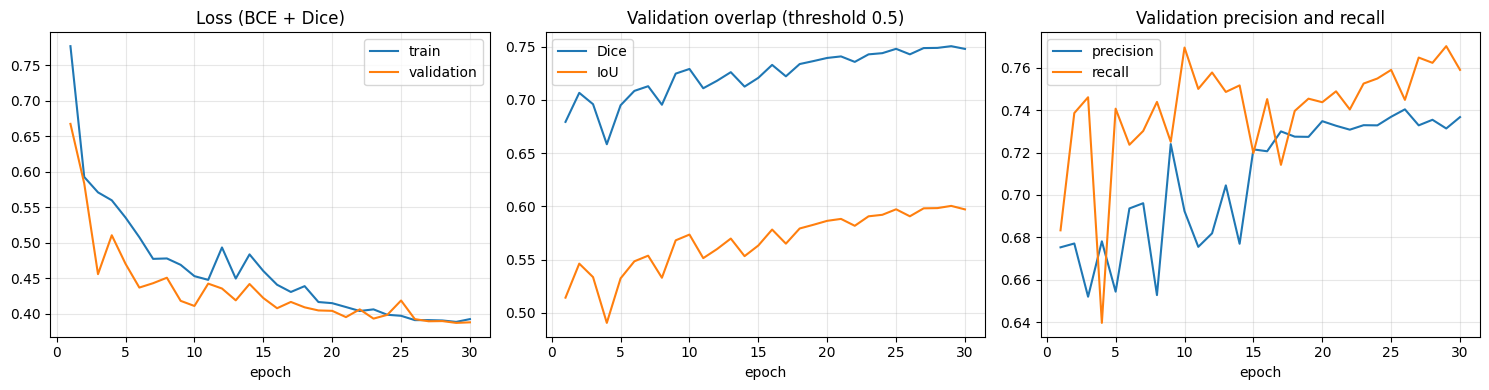

In [8]:
# Cell 8 — Learning curves
h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(h["epoch"], h["train_loss"], label="train")
axes[0].plot(h["epoch"], h["val_loss"], label="validation")
axes[0].set_title("Loss (BCE + Dice)")
axes[0].legend()
axes[1].plot(h["epoch"], h["val_dice"], label="Dice")
axes[1].plot(h["epoch"], h["val_iou"], label="IoU")
axes[1].set_title("Validation overlap (threshold 0.5)")
axes[1].legend()
axes[2].plot(h["epoch"], h["val_precision"], label="precision")
axes[2].plot(h["epoch"], h["val_recall"], label="recall")
axes[2].set_title("Validation precision and recall")
axes[2].legend()
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / f"curves_{ENCODER}_seed{SEED}.png", dpi=120)
plt.show()

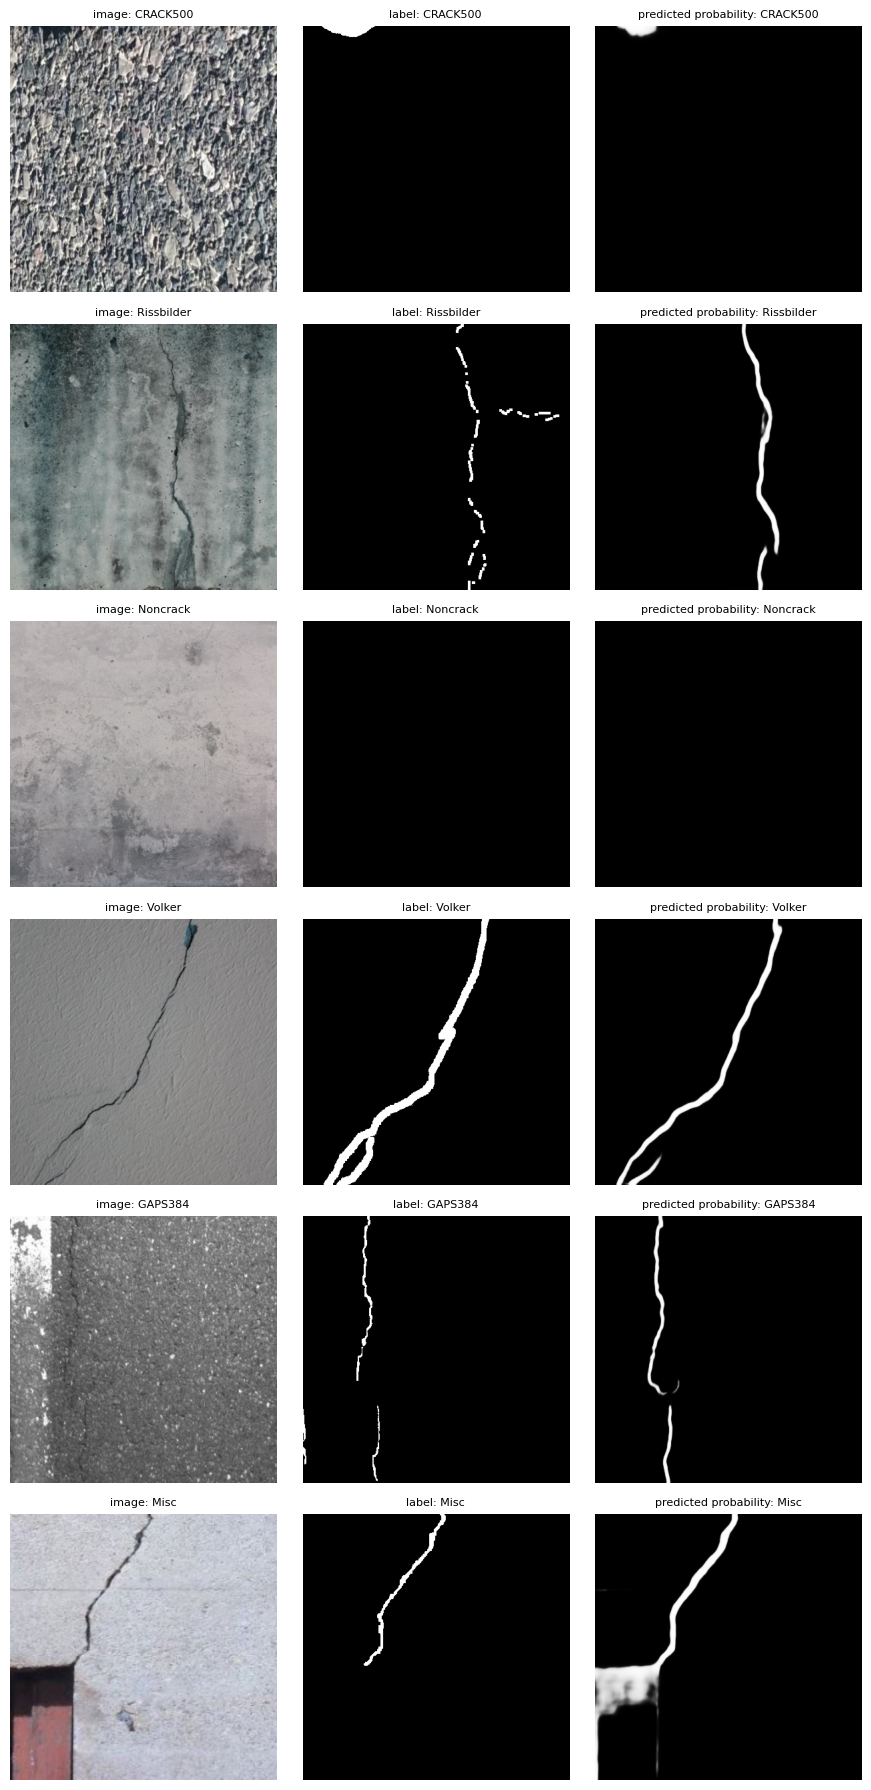

In [9]:
# Cell 9 — Predictions of the best model on validation images
model.load_state_dict(torch.load(OUT_DIR / f"best_{ENCODER}_seed{SEED}.pth", map_location=DEVICE))
model.eval()
val_df = df[df["split"] == "val"].reset_index(drop=True)
rng = np.random.default_rng(0)
picks = [rng.choice(val_df.index[val_df["source"] == s]) for s in TRAIN_SOURCES]
val_ds = CrackDataset(val_df, eval_tf)
MEAN, STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
fig, axes = plt.subplots(len(picks), 3, figsize=(9, 3 * len(picks)))
for r, i in enumerate(picks):
    image, mask = val_ds[i]
    with torch.no_grad():
        prob = torch.sigmoid(model(image[None].to(DEVICE)).float())[0, 0].cpu()
    crop = slice(BORDER, -BORDER)
    img = np.clip(image.permute(1, 2, 0).numpy() * STD + MEAN, 0, 1)[crop, crop]
    for ax, (title, shown) in zip(axes[r], [("image", img), ("label", mask[0][crop, crop]),
                                            ("predicted probability", prob[crop, crop])]):
        ax.imshow(shown, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{title}: {val_df.loc[i, 'source']}", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / f"val_examples_{ENCODER}_seed{SEED}.png", dpi=100)
plt.show()